<a href="https://colab.research.google.com/github/Juanma-dev-tech/AprendizajeAutomatico2/blob/main/TP3/TP3_FrozenLake.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico: Aprendizaje por Refuerzo en FrozenLake

## Instalar librerias

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import random
import seaborn as sns
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

## Reproducibilidad

In [2]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

## Crear el entorno

In [3]:
env = gym.make('FrozenLake-v1', desc=None, map_name="4x4", is_slippery=True, render_mode='ansi')
print("🏔️ ENTORNO FROZENLAKE")
print("=" * 50)
print(f"Número de estados: {env.observation_space.n}")
print(f"Número de acciones: {env.action_space.n}")
print(f"Acciones: {['Izquierda', 'Abajo', 'Derecha', 'Arriba']}")

🏔️ ENTORNO FROZENLAKE
Número de estados: 16
Número de acciones: 4
Acciones: ['Izquierda', 'Abajo', 'Derecha', 'Arriba']


## Mostrar el mapa

In [4]:
print("\n🗺️ MAPA DEL ENTORNO:")
env.reset()
print(env.render())
print("\nLeyenda:")
print("S = Start (Inicio)")
print("F = Frozen (Hielo seguro)")
print("H = Hole (Hoyo - termina episodio)")
print("G = Goal (Objetivo - +1 recompensa)")


🗺️ MAPA DEL ENTORNO:

SFFF
FHFH
FFFH
HFFG


Leyenda:
S = Start (Inicio)
F = Frozen (Hielo seguro)
H = Hole (Hoyo - termina episodio)
G = Goal (Objetivo - +1 recompensa)


## Función para convertir estado numérico a posición (fila, columna)

In [5]:

def estado_a_posicion(estado):
  return estado // 4, estado % 4

## Funcion para visualizar politica

In [6]:
def visualizar_politica(policy, title="Política"):
  acciones_simbolos = ['←', '↓', '→', '↑']
  grid = np.array(acciones_simbolos)[policy].reshape(4, 4)
  plt.figure(figsize=(6, 6))
  plt.imshow(np.ones((4, 4)), cmap='Blues', alpha=0.3)

  for i in range(4):
      for j in range(4):
          estado = i * 4 + j
          if estado == 0:  # Start
              plt.text(j, i, f'S\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado == 15:  # Goal
              plt.text(j, i, f'G\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado in [5, 7, 11, 12]:  # Holes
              plt.text(j, i, f'H\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold', color='red')
          else:
              plt.text(j, i, grid[i,j], ha='center', va='center', fontsize=16)

  plt.xlim(-0.5, 3.5)
  plt.ylim(-0.5, 3.5)
  plt.xticks([])
  plt.yticks([])
  plt.title(title, fontsize=16)
  plt.grid(True, alpha=0.3)
  plt.show()

## Politica aleatoria

In [7]:
class PoliticaAleatoria:
  """Política que selecciona acciones completamente al azar"""
  def __init__(self, n_acciones):
      self.n_acciones = n_acciones
      self.nombre = "Política Aleatoria"

  def seleccionar_accion(self, estado):
      """Selecciona una acción aleatoria"""
      return np.random.randint(self.n_acciones)

  def entrenar(self, env, episodios=1000):
      """La política aleatoria no se entrena, solo evaluamos su desempeño"""
      print(f"🎲 Evaluando {self.nombre}...")
      recompensas = []
      exitos = 0

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado)
              estado, recompensa, terminado, truncated, _ = env.step(accion)
              recompensa_total += recompensa
              pasos += 1

              if truncated:
                  terminado = True

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)

          if (episodio + 1) % 200 == 0:
              tasa_exito = exitos / (episodio + 1)
              print(f"Episodio {episodio + 1}: Tasa de éxito = {tasa_exito:.3f}")

      tasa_exito_final = exitos / episodios
      print(f"\n📊 Resultados {self.nombre}:")
      print(f"Tasa de éxito final: {tasa_exito_final:.3f}")
      print(f"Recompensa promedio: {np.mean(recompensas):.3f}")

      return recompensas, tasa_exito_final

## Crear y evaluar política aleatoria

In [8]:
agente_aleatorio = PoliticaAleatoria(env.action_space.n)
recompensas_aleatorio, tasa_exito_aleatorio = agente_aleatorio.entrenar(env, episodios=1000)

🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.020
Episodio 400: Tasa de éxito = 0.013
Episodio 600: Tasa de éxito = 0.008
Episodio 800: Tasa de éxito = 0.010
Episodio 1000: Tasa de éxito = 0.010

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.010
Recompensa promedio: 0.010


## Visualizar política aleatoria (todas las acciones tienen la misma probabilidad)

In [9]:

politica_aleatoria = np.random.randint(0, 4, 16)  # Solo para visualización

In [10]:
politica_aleatoria

array([0, 2, 1, 2, 1, 3, 1, 1, 1, 0, 1, 3, 3, 3, 1, 2])

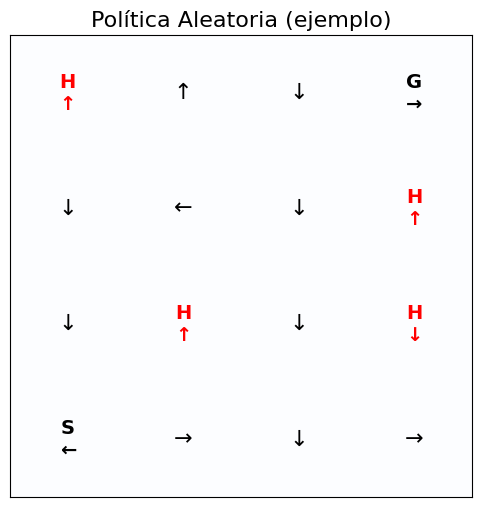

In [11]:

visualizar_politica(politica_aleatoria, "Política Aleatoria (ejemplo)")

## Politica Q-learning

In [12]:
class QLearningTabular:
  """Implementación de Q-Learning con tabla Q explícita"""
  def __init__(self, n_estados, n_acciones, lr=0.1, gamma=0.95, epsilon=1.0):
      self.n_estados = n_estados
      self.n_acciones = n_acciones
      self.lr = lr  # learning rate
      self.gamma = gamma  # factor de descuento
      self.epsilon = epsilon  # exploración inicial
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.nombre = "Q-Learning Tabular"

      # Inicializar tabla Q
      self.q_table = np.zeros((n_estados, n_acciones))

      # Para tracking
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción con epsilon-greedy"""
      if entrenando and np.random.random() < self.epsilon:
          return np.random.randint(self.n_acciones)  # Exploración
      else:
          return np.argmax(self.q_table[estado])  # Explotación

  def actualizar_q(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Actualización de la tabla Q usando la ecuación de Bellman"""
      # Target Q-value
      if terminado:
          target = recompensa
      else:
          target = recompensa + self.gamma * np.max(self.q_table[siguiente_estado])

      # Actualización Q-Learning
      self.q_table[estado, accion] += self.lr * (target - self.q_table[estado, accion])

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener la política greedy de la tabla Q"""
      return np.argmax(self.q_table, axis=1)

  def entrenar(self, env, episodios=10000):
      """Entrenamiento del agente Q-Learning"""
      print(f"🧠 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)  # Para promedios móviles

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Actualizar tabla Q
              self.actualizar_q(estado, accion, recompensa, siguiente_estado, terminado)

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 1000 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito (últimos 100) = {tasa_exito:.3f}, Epsilon = {self.epsilon:.3f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado sin exploración"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)  # Sin exploración
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Crear y entrenar agente Q-Learning

In [13]:

agente_qlearning = QLearningTabular(env.observation_space.n, env.action_space.n,lr=0.1, gamma=0.95, epsilon=1.0)
recompensas_qlearning = agente_qlearning.entrenar(env, episodios=1000)

🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.160, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!


## Evaluar agente entrenado

In [14]:

tasa_exito_qlearning, _ = agente_qlearning.evaluar(env, episodios=1000)


📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.213
Pasos promedio: 22.3


## Visualizar política aprendida

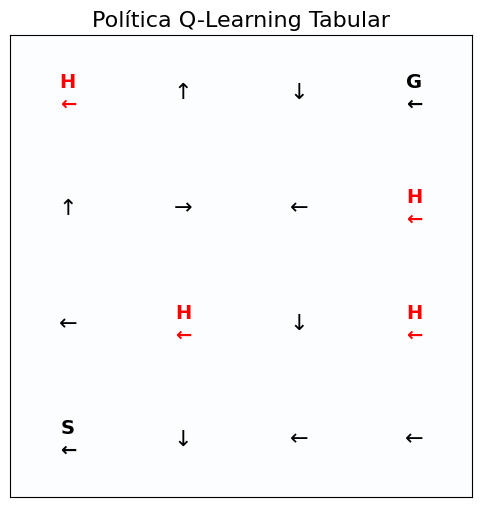

In [15]:

politica_qlearning = agente_qlearning.obtener_politica()
visualizar_politica(politica_qlearning, "Política Q-Learning Tabular")

## Visualizar tabla Q como heatmap

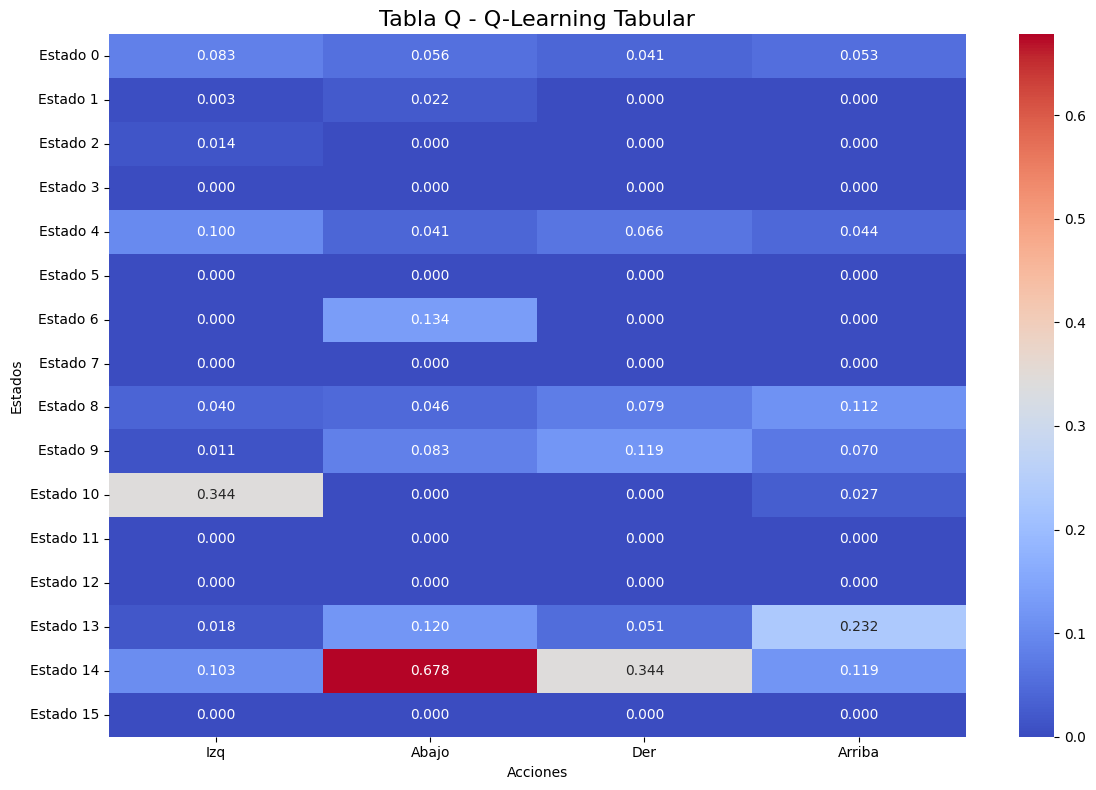

In [16]:

plt.figure(figsize=(12, 8))
sns.heatmap(agente_qlearning.q_table, annot=True, fmt='.3f', cmap='coolwarm',
xticklabels=['Izq', 'Abajo', 'Der', 'Arriba'],
yticklabels=[f'Estado {i}' for i in range(16)])
plt.title('Tabla Q - Q-Learning Tabular', fontsize=16)
plt.xlabel('Acciones')
plt.ylabel('Estados')
plt.tight_layout()
plt.show()

## Mostrar valores Q para estados importantes
-

In [17]:
print("🎯 VALORES Q PARA ESTADOS CLAVE:")
print("-" * 40)
estados_clave = [0, 5, 7, 11, 12, 14, 15]  # Start, Holes, Goal
acciones_nombres = ['Izquierda', 'Abajo', 'Derecha', 'Arriba']
for estado in estados_clave:
  if estado == 0:
    tipo = "START"
  elif estado == 15:
    tipo = "GOAL"
  elif estado in [5, 7, 11, 12]:
    tipo = "HOLE"
  else:
    tipo = "NORMAL"

  print(f"\nEstado {estado} ({tipo}):")
  for accion, valor in enumerate(agente_qlearning.q_table[estado]):
       print(f"  {acciones_nombres[accion]}: {valor:.3f}")

🎯 VALORES Q PARA ESTADOS CLAVE:
----------------------------------------

Estado 0 (START):
  Izquierda: 0.083
  Abajo: 0.056
  Derecha: 0.041
  Arriba: 0.053

Estado 5 (HOLE):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000

Estado 7 (HOLE):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000

Estado 11 (HOLE):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000

Estado 12 (HOLE):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000

Estado 14 (NORMAL):
  Izquierda: 0.103
  Abajo: 0.678
  Derecha: 0.344
  Arriba: 0.119

Estado 15 (GOAL):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000


# Deep Q-Network

## red DQN

In [18]:
class DQN(nn.Module):
  """Red neuronal para aproximar la función Q"""
  def __init__(self, input_size, hidden_size, output_size):
      super(DQN, self).__init__()
      self.network = nn.Sequential(
          nn.Linear(input_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, output_size)
      )

  def forward(self, x):
      return self.network(x)

## DQNAgent

In [19]:
class DQNAgent:
  """Agente Deep Q-Network con Experience Replay y Target Network"""
  def __init__(self, state_size, action_size, lr=0.001, gamma=0.95, epsilon=1.0):
      self.state_size = state_size
      self.action_size = action_size
      self.gamma = gamma
      self.epsilon = epsilon
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.learning_rate = lr
      self.nombre = "Deep Q-Network (DQN)"

      # Configuración del dispositivo
      self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
      print(f"🖥️ Usando dispositivo: {self.device}")

      # Redes neuronales
      hidden_size = 128
      self.q_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.target_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

      # Inicializar target network con mismos pesos
      self.update_target_network()

      # Experience Replay
      self.memory = deque(maxlen=10000)
      self.batch_size = 32

      # Frecuencia de actualización de target network
      self.update_target_frequency = 100
      self.step_count = 0

      # Para tracking
      self.losses = []
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def state_to_onehot(self, state):
      """Convertir estado discreto a representación one-hot"""
      onehot = np.zeros(self.state_size)
      onehot[state] = 1.0
      return onehot

  def remember(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Almacenar experiencia en el buffer de replay"""
      estado_onehot = self.state_to_onehot(estado)
      siguiente_estado_onehot = self.state_to_onehot(siguiente_estado)

      self.memory.append((estado_onehot, accion, recompensa, siguiente_estado_onehot, terminado))

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción epsilon-greedy usando la red neuronal"""
      if entrenando and np.random.random() < self.epsilon:
          return random.randrange(self.action_size)

      # Convertir estado a tensor
      estado_onehot = self.state_to_onehot(estado)
      estado_tensor = torch.FloatTensor(estado_onehot).unsqueeze(0).to(self.device)

      # Forward pass
      with torch.no_grad():
          q_values = self.q_network(estado_tensor)

      return np.argmax(q_values.cpu().data.numpy())

  def replay(self):
      """Experience replay para entrenar la red"""
      if len(self.memory) < self.batch_size:
          return

      # Muestrear batch aleatorio
      batch = random.sample(self.memory, self.batch_size)
      estados = torch.FloatTensor([e[0] for e in batch]).to(self.device)
      acciones = torch.LongTensor([e[1] for e in batch]).to(self.device)
      recompensas = torch.FloatTensor([e[2] for e in batch]).to(self.device)
      siguientes_estados = torch.FloatTensor([e[3] for e in batch]).to(self.device)
      terminados = torch.BoolTensor([e[4] for e in batch]).to(self.device)

      # Q-values actuales
      current_q_values = self.q_network(estados).gather(1, acciones.unsqueeze(1))

      # Q-values objetivo usando target network
      with torch.no_grad():
          next_q_values = self.target_network(siguientes_estados).max(1)[0]
          target_q_values = recompensas + (self.gamma * next_q_values * ~terminados)

      # Calcular pérdida
      loss = F.mse_loss(current_q_values.squeeze(), target_q_values)

      # Backpropagation
      self.optimizer.zero_grad()
      loss.backward()
      self.optimizer.step()

      # Guardar pérdida para análisis
      self.losses.append(loss.item())

  def update_target_network(self):
      """Actualizar la target network con pesos de la red principal"""
      self.target_network.load_state_dict(self.q_network.state_dict())

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener política greedy de la red entrenada"""
      politica = []
      for estado in range(self.state_size):
          accion = self.seleccionar_accion(estado, entrenando=False)
          politica.append(accion)
      return np.array(politica)

  def entrenar(self, env, episodios=2000):
      """Entrenamiento del agente DQN"""
      print(f"🤖 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Almacenar experiencia
              self.remember(estado, accion, recompensa, siguiente_estado, terminado)

              # Entrenar la red
              self.replay()

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1
              self.step_count += 1

              # Actualizar target network periódicamente
              if self.step_count % self.update_target_frequency == 0:
                  self.update_target_network()

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 200 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              loss_promedio = np.mean(self.losses[-100:]) if len(self.losses) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito = {tasa_exito:.3f}, "
                    f"Epsilon = {self.epsilon:.3f}, Loss = {loss_promedio:.4f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Entrenar deep DQN

In [20]:
agente_dqn = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.95, epsilon=1.0)
recompensas_dqn = agente_dqn.entrenar(env, episodios=1000)

🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.070, Epsilon = 0.367, Loss = 0.0102
Episodio 400: Tasa éxito = 0.230, Epsilon = 0.135, Loss = 0.0072
Episodio 600: Tasa éxito = 0.500, Epsilon = 0.049, Loss = 0.0088
Episodio 800: Tasa éxito = 0.460, Epsilon = 0.018, Loss = 0.0076
Episodio 1000: Tasa éxito = 0.650, Epsilon = 0.010, Loss = 0.0087

✅ Entrenamiento Deep Q-Network (DQN) completado!


## Evaluar agente Deep DQN

In [21]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)


📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.707
Pasos promedio: 40.8


## Visualizar política aprendida

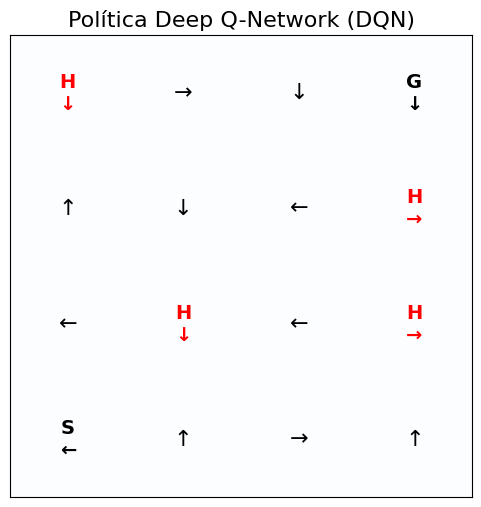

In [22]:

politica_dqn = agente_dqn.obtener_politica()
visualizar_politica(politica_dqn, "Política Deep Q-Network (DQN)")


# Comparación de resultados

## Comparación final tasa de éxito

In [23]:
print("🏆 COMPARACIÓN FINAL DE AGENTES")
print("=" * 50)
print(f"Política Aleatoria:    Tasa de éxito = {tasa_exito_aleatorio:.3f}")
print(f"Q-Learning Tabular:    Tasa de éxito = {tasa_exito_qlearning:.3f}")
print(f"Deep Q-Network (DQN):  Tasa de éxito = {tasa_exito_dqn:.3f}")

🏆 COMPARACIÓN FINAL DE AGENTES
Política Aleatoria:    Tasa de éxito = 0.010
Q-Learning Tabular:    Tasa de éxito = 0.213
Deep Q-Network (DQN):  Tasa de éxito = 0.707


## Crear gráficas de comparación


Crear gráficas de comparación


### 1. Curvas de aprendizaje

In [24]:
len(recompensas_aleatorio)

1000

In [25]:
len(recompensas_qlearning)

1000

In [26]:
len(recompensas_dqn)

1000

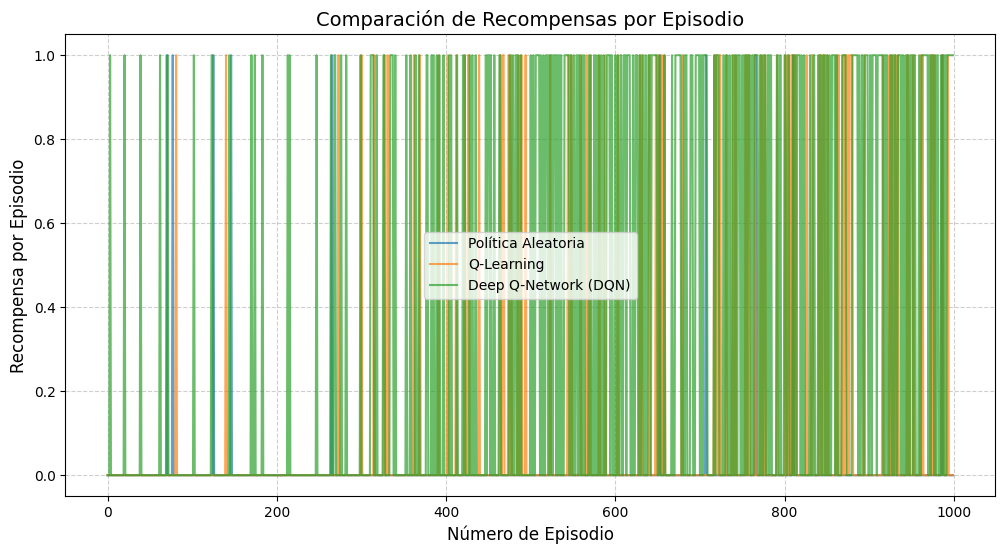

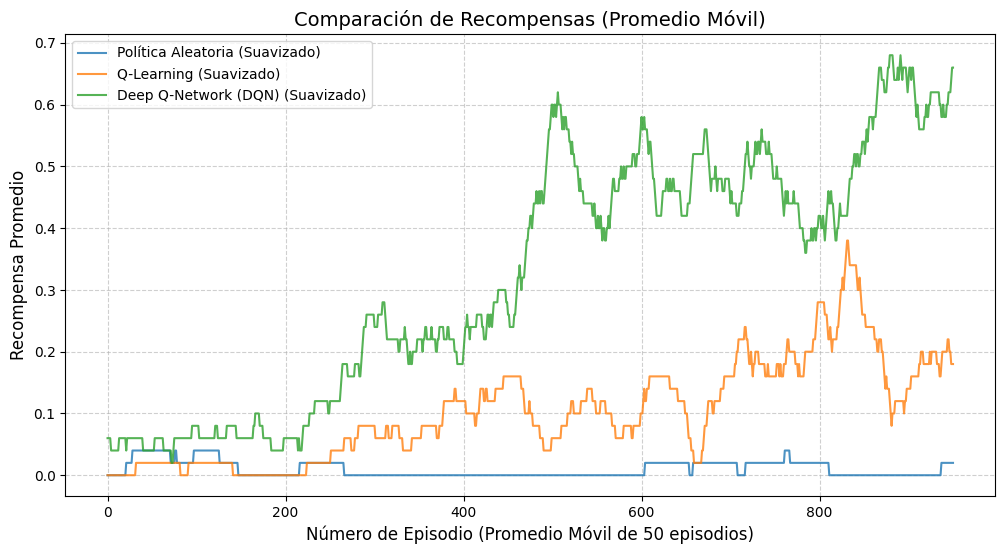

In [27]:
# prompt: crear gráfico que compare recompensas_aleatorio, recompensas_qlearning y recompensas_dqn. Eje x es nro de episodio y el eje Y valor de la recompensa

import matplotlib.pyplot as plt
import numpy as np
# Asegurar que las listas de recompensas tengan la misma longitud para la gráfica
# Tomaremos la longitud mínima si son diferentes
min_len = min(len(recompensas_aleatorio), len(recompensas_qlearning), len(recompensas_dqn))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio[:min_len], label='Política Aleatoria', alpha=0.7)
plt.plot(recompensas_qlearning[:min_len], label='Q-Learning', alpha=0.7)
plt.plot(recompensas_dqn[:min_len], label='Deep Q-Network (DQN)', alpha=0.7)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Recompensa por Episodio', fontsize=12)
plt.title('Comparación de Recompensas por Episodio', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Para suavizar la gráfica, se puede usar un promedio móvil
def moving_average(data, window_size):
    if len(data) < window_size:
        return data
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

window = 50  # Tamaño de la ventana para el promedio móvil

recompensas_aleatorio_suavizado = moving_average(recompensas_aleatorio, window)
recompensas_qlearning_suavizado = moving_average(recompensas_qlearning, window)
recompensas_dqn_suavizado = moving_average(recompensas_dqn, window)

# Ajustar la longitud mínima para las series suavizadas
min_len_suavizado = min(len(recompensas_aleatorio_suavizado), len(recompensas_qlearning_suavizado), len(recompensas_dqn_suavizado))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio_suavizado[:min_len_suavizado], label='Política Aleatoria (Suavizado)', alpha=0.8)
plt.plot(recompensas_qlearning_suavizado[:min_len_suavizado], label='Q-Learning (Suavizado)', alpha=0.8)
plt.plot(recompensas_dqn_suavizado[:min_len_suavizado], label='Deep Q-Network (DQN) (Suavizado)', alpha=0.8)

plt.xlabel(f'Número de Episodio (Promedio Móvil de {window} episodios)', fontsize=12)
plt.ylabel('Recompensa Promedio', fontsize=12)
plt.title('Comparación de Recompensas (Promedio Móvil)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



### 2. Comparación de tasas de éxito

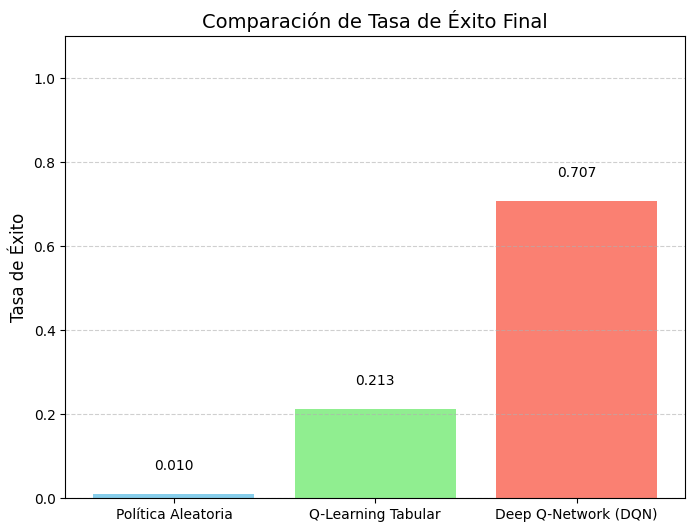

In [28]:
# prompt: comparar tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn en un gráfico de barras

import matplotlib.pyplot as plt
metricas = ['Política Aleatoria', 'Q-Learning Tabular', 'Deep Q-Network (DQN)']
tasas_exito = [tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas_exito, color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('Tasa de Éxito', fontsize=12)
plt.title('Comparación de Tasa de Éxito Final', fontsize=14)
plt.ylim(0, 1.1) # Limitar el eje Y de 0 a 1.1 para mejor visualización

# Añadir los valores de las tasas de éxito encima de cada barra
for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.3f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


### Evolución de Epsilon (solo para algoritmos que usan exploración)

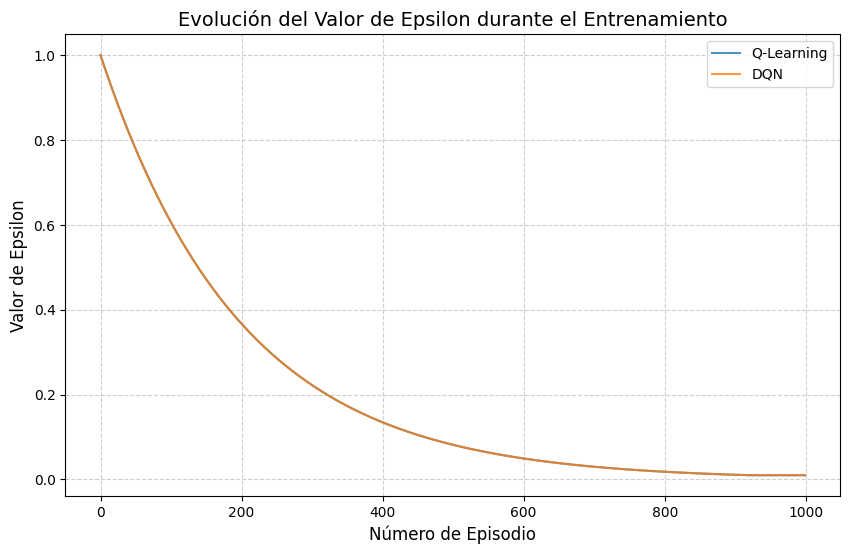

In [29]:
# prompt: Crear un gráfico para comparar agente_qlearning.epsilons y agente_qlearning.epsilons siendo x el nro de episodios y el eje Y el valor de epsilon

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(agente_qlearning.epsilons, label='Q-Learning', alpha=0.8)
plt.plot(agente_dqn.epsilons, label='DQN', alpha=0.8)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Valor de Epsilon', fontsize=12)
plt.title('Evolución del Valor de Epsilon durante el Entrenamiento', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### DQN pérdida

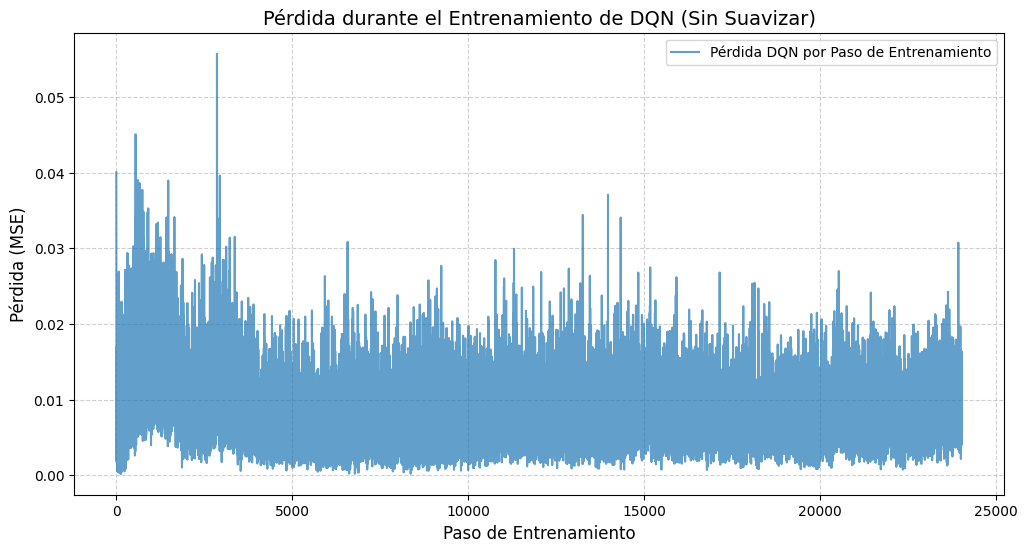

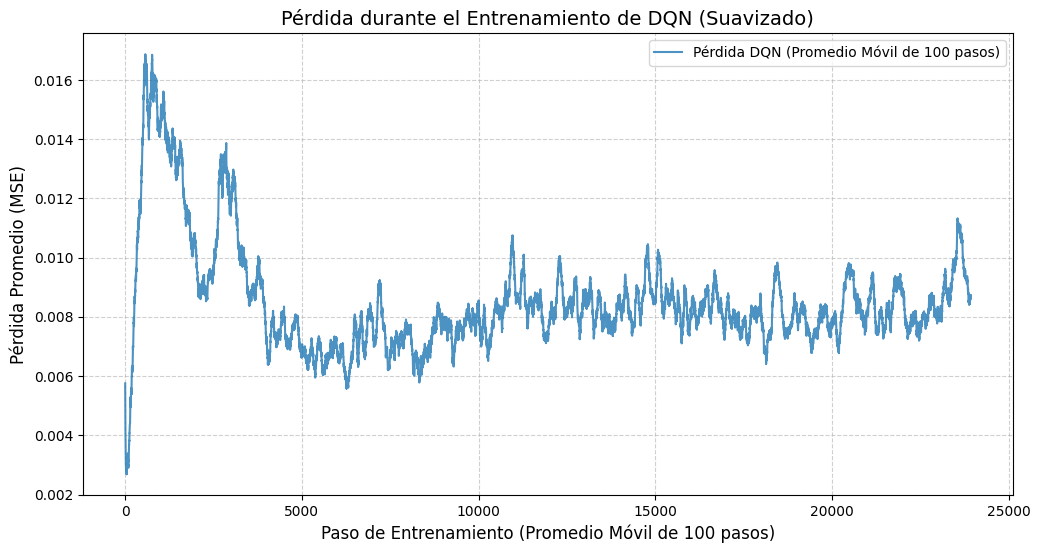

In [30]:
# prompt: Graficar agente_dqn.losses que representa la pérdida durante el entrenamiento de DQN. Mostrar con y sin promedio móvil

import matplotlib.pyplot as plt
# Graficar la pérdida del agente DQN
plt.figure(figsize=(12, 6))
plt.plot(agente_dqn.losses, label='Pérdida DQN por Paso de Entrenamiento', alpha=0.7)
plt.xlabel('Paso de Entrenamiento', fontsize=12)
plt.ylabel('Pérdida (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Sin Suavizar)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Graficar la pérdida con promedio móvil para suavizar
window_loss = 100 # Tamaño de la ventana para el promedio móvil de la pérdida
losses_dqn_suavizado = moving_average(agente_dqn.losses, window_loss)

plt.figure(figsize=(12, 6))
plt.plot(losses_dqn_suavizado, label=f'Pérdida DQN (Promedio Móvil de {window_loss} pasos)', alpha=0.8)
plt.xlabel(f'Paso de Entrenamiento (Promedio Móvil de {window_loss} pasos)', fontsize=12)
plt.ylabel('Pérdida Promedio (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Suavizado)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Ejercitación

## A) Modifique el entrenamiento de los agentes para entrenar por más episodios. Evalue su desempeño. ¿ Mejora o empeora ?






### Ejercicio A — Comparación de resultados con más episodios

Para este experimento reutilicé las clases y métodos del notebook original, creando nuevas instancias de los agentes y aumentando la cantidad de episodios de 1.000 a 2.000.

Mantuve los demás hiperparámetros sin cambios para analizar cómo influye la cantidad de episodios en el desempeño de cada agente.

A continuación, comparo las tasas de éxito obtenidas en ambas ejecuciones mediante un gráfico de barras.

In [32]:
# Ejercicio A - Aumento de episodios
# Se reutilizan las clases y métodos implementados en el
# notebook original de la profesora Ana Laura Diedrichs.
# Se crean nuevas instancias de los agentes para experimentar
# con 2000 episodios, manteniendo los demás hiperparámetros.
# El objetivo es comparar los resultados con la ejecución inicial.

episodios_A = 2000

# Política aleatoria: solo evaluación
agente_aleatorio_A = PoliticaAleatoria(env.action_space.n)
recompensas_aleatorio_A, tasa_aleatorio_A = agente_aleatorio_A.entrenar(
    env, episodios=episodios_A
)

# Q-Learning: entrenamiento y evaluación
agente_qlearning_A = QLearningTabular(
    env.observation_space.n,
    env.action_space.n,
    lr=0.1,
    gamma=0.95,
    epsilon=1.0
)

recompensas_qlearning_A = agente_qlearning_A.entrenar(
    env, episodios=episodios_A
)

tasa_qlearning_A, _ = agente_qlearning_A.evaluar(
    env, episodios=1000
)

# DQN: entrenamiento y evaluación
agente_dqn_A = DQNAgent(
    env.observation_space.n,
    env.action_space.n,
    lr=0.001,
    gamma=0.95,
    epsilon=1.0
)

recompensas_dqn_A = agente_dqn_A.entrenar(
    env, episodios=episodios_A
)

tasa_dqn_A, _ = agente_dqn_A.evaluar(
    env, episodios=1000
)


🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.010
Episodio 400: Tasa de éxito = 0.020
Episodio 600: Tasa de éxito = 0.017
Episodio 800: Tasa de éxito = 0.018
Episodio 1000: Tasa de éxito = 0.019
Episodio 1200: Tasa de éxito = 0.016
Episodio 1400: Tasa de éxito = 0.017
Episodio 1600: Tasa de éxito = 0.016
Episodio 1800: Tasa de éxito = 0.015
Episodio 2000: Tasa de éxito = 0.015

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.015
Recompensa promedio: 0.015
🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.540, Epsilon = 0.010
Episodio 2000: Tasa éxito (últimos 100) = 0.430, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!
📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.593
Pasos promedio: 35.8
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.030, Epsilon = 0.367, Loss = 0.0088
Episodio 400: Tasa éxito = 0.210, Epsilon = 0.135, Loss = 0.0059
Episodio 600: Tasa éxito = 0.

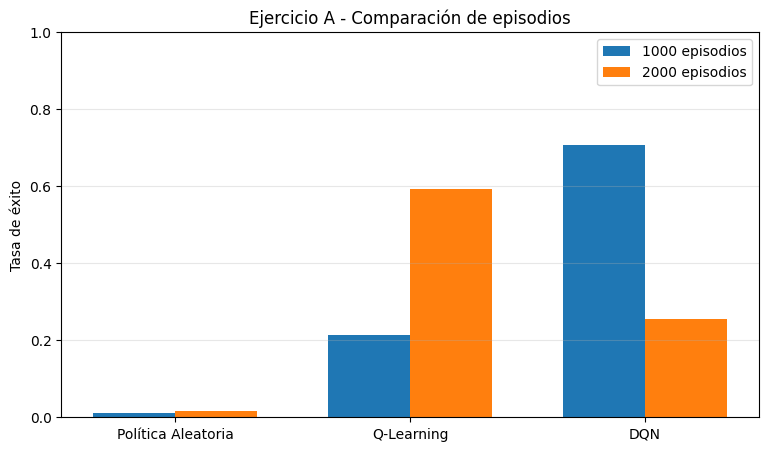

In [34]:
# @title

# Ejercicio A - Comparación de resultados
# Se comparan los agentes originales con los nuevos.
# Se reutilizan las tasas obtenidas en el notebook de la profesora.

agentes = ['Política Aleatoria', 'Q-Learning', 'DQN']

tasas_1000 = [
    tasa_exito_aleatorio,
    tasa_exito_qlearning,
    tasa_exito_dqn
]

tasas_2000 = [
    tasa_aleatorio_A,
    tasa_qlearning_A,
    tasa_dqn_A
]

x = np.arange(len(agentes))
ancho = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - ancho/2, tasas_1000, ancho, label='1000 episodios')
plt.bar(x + ancho/2, tasas_2000, ancho, label='2000 episodios')

plt.xticks(x, agentes)
plt.ylabel('Tasa de éxito')
plt.title('Ejercicio A - Comparación de episodios')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()


In [33]:
# Comprobar estabilidad de la evaluación DQN
for i in range(3):
    print(f"\nEvaluación {i + 1}")
    agente_dqn_A.evaluar(env, episodios=1000)


Evaluación 1
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.261
Pasos promedio: 16.0

Evaluación 2
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.294
Pasos promedio: 16.4

Evaluación 3
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.303
Pasos promedio: 15.8


### Conclusiones del ejercicio A

Al aumentar los episodios de 1.000 a 2.000, obtuve los siguientes resultados:

-**Política aleatoria:** pasó del 1% al 1,5%. Esta diferencia no representa aprendizaje, ya que el agente sigue eligiendo acciones al azar.

-**Q-Learning:** mejoró del 21,3% al 59,3%, mostrando un mejor desempeño con más episodios en este experimento.

-**DQN:** bajó del 70,7% al 25,5%, por lo que aumentar los episodios no produjo una mejora en esta ejecución.

En DQN observé además que la tasa de éxito de los últimos 100 episodios de entrenamiento fue del 67%, bastante superior al 25,5% obtenido en la evaluación final.

Para investigar esta diferencia, repetí tres veces la evaluación del mismo modelo, sin volver a entrenarlo. Obtuve tasas del 26,1%, 29,4% y 30,3%, lo que confirmó que el desempeño de la política final se mantenía bastante por debajo del observado al finalizar el entrenamiento.

**Concluyo que aumentar la cantidad de episodios no garantiza una mejora del desempeño.** Los resultados también pueden verse afectados por la aleatoriedad del entorno y del entrenamiento. Para determinar si estas diferencias se mantienen, sería necesario repetir los entrenamientos con distintas semillas.

## B) Considere modificar el modelo DQN el hiperparámetro gamma: un valor bajo, uno medio y uno alto. Entrene los tres modelos y compare los resultados. Comparta sus conclusiones

### Ejercicio B — Comparación de distintos valores de gamma en DQN

En este experimento reutilicé la implementación DQN del notebook original para analizar cómo influye el factor de descuento gamma en el desempeño del agente.

Seleccioné tres valores: 0.20 (bajo), 0.60 (medio) y 0.99 (alto).

Voy a entrenar cada modelo desde cero durante 1.000 episodios, manteniendo los demás hiperparámetros constantes y utilizando la misma semilla inicial. Luego evaluaré cada modelo durante 1.000 episodios para comparar sus tasas de éxito.

In [35]:

# Ejercicio B - Comparación de gamma
# Reutilizo DQNAgent del notebook original.
# Cambio únicamente gamma entre experimentos.

gammas_B = [0.20, 0.60, 0.99]
resultados_B = {}
modelos_B = {}

for gamma in gammas_B:
    print(f"\n{'=' * 45}")
    print(f"Experimento con gamma = {gamma}")

    # Reiniciar semillas para comparar los experimentos
    np.random.seed(42)
    random.seed(42)
    torch.manual_seed(42)
    env.reset(seed=42)

    # Crear un agente nuevo
    agente = DQNAgent(
        env.observation_space.n,
        env.action_space.n,
        lr=0.001,
        gamma=gamma,
        epsilon=1.0
    )

    # Entrenar durante 1000 episodios
    agente.entrenar(env, episodios=1000)

    # Evaluar sin exploración
    env.reset(seed=123)
    tasa, _ = agente.evaluar(env, episodios=1000)

    # Conservar los resultados y el modelo
    resultados_B[gamma] = tasa
    modelos_B[gamma] = agente

print("\nRESULTADOS DEL EJERCICIO B")
for gamma, tasa in resultados_B.items():
    print(f"Gamma {gamma}: tasa de éxito = {tasa:.1%}")



Experimento con gamma = 0.2
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.020, Epsilon = 0.367, Loss = 0.0010
Episodio 400: Tasa éxito = 0.010, Epsilon = 0.135, Loss = 0.0015
Episodio 600: Tasa éxito = 0.010, Epsilon = 0.049, Loss = 0.0014
Episodio 800: Tasa éxito = 0.020, Epsilon = 0.018, Loss = 0.0008
Episodio 1000: Tasa éxito = 0.050, Epsilon = 0.010, Loss = 0.0020

✅ Entrenamiento Deep Q-Network (DQN) completado!
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.000
Pasos promedio: 12.3

Experimento con gamma = 0.6
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.050, Epsilon = 0.367, Loss = 0.0041
Episodio 400: Tasa éxito = 0.070, Epsilon = 0.135, Loss = 0.0034
Episodio 600: Tasa éxito = 0.080, Epsilon = 0.049, Loss = 0.0036
Episodio 800: Tasa éxito = 0.090, Epsilon = 0.018, Loss = 0.0042
Episodio 1000: Tasa éxito = 0.140, Epsilon = 0.010, Loss = 0.0045

✅ Entrenamiento Deep Q-Network (D

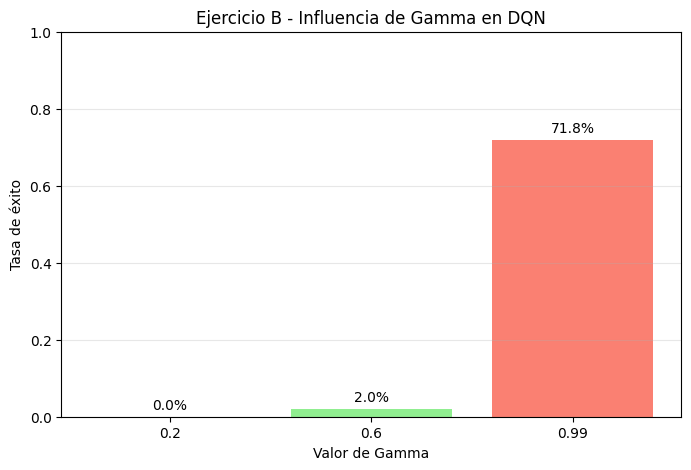

In [36]:

# Ejercicio B - Comparación de tasas de éxito según gamma

gammas = list(resultados_B.keys())
tasas = list(resultados_B.values())

plt.figure(figsize=(8, 5))
barras = plt.bar(
    [str(g) for g in gammas],
    tasas,
    color=['skyblue', 'lightgreen', 'salmon']
)

plt.title('Ejercicio B - Influencia de Gamma en DQN')
plt.xlabel('Valor de Gamma')
plt.ylabel('Tasa de éxito')
plt.ylim(0, 1)

for barra, tasa in zip(barras, tasas):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.02,
        f'{tasa:.1%}',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.show()


### Conclusiones del ejercicio B

Para este experimento entrené tres modelos DQN con valores de gamma de 0.20, 0.60 y 0.99, manteniendo los demás hiperparámetros constantes.

Los resultados fueron bastante diferentes:

-**Gamma 0.20:** obtuvo un 0% de éxito.

-**Gamma 0.60:** alcanzó un 2% de éxito.

-**Gamma 0.99:** consiguió un 71,8% de éxito.

Observé que el modelo con gamma alto obtuvo el mejor desempeño. Esto tiene sentido porque en FrozenLake la recompensa se recibe al llegar a la meta, después de realizar varios movimientos.

Un gamma alto permite darle mayor importancia a esas recompensas futuras, mientras que con valores bajos su influencia disminuye rápidamente.

También observé que una pérdida de entrenamiento pequeña no necesariamente significa que el agente haya aprendido una buena política.

**Concluyo que gamma influyó considerablemente en el desempeño de DQN en este experimento**, y que un valor alto resultó más conveniente para este entorno. Para generalizar esta conclusión sería necesario repetir los entrenamientos con distintas semillas.

## C) Lo mismo que en B) pero para el hiperparámetro alpha.

### Ejercicio C — Comparación de distintos valores de alpha en DQN

Para este experimento reutilicé la implementación DQN del notebook original, modificando la tasa de aprendizaje (`lr`), que representa alpha en este caso.

Seleccioné tres valores: 0.0001 (bajo), 0.001 (medio) y 0.01 (alto).

Voy a entrenar tres modelos nuevos durante 1.000 episodios cada uno, manteniendo gamma en 0.95 y los demás hiperparámetros constantes.

Después evaluaré los modelos durante 1.000 episodios para comparar sus tasas de éxito y analizar cómo influye la tasa de aprendizaje en los resultados.

In [37]:

# Ejercicio C - Comparación de alpha (learning rate)
# Reutilizo DQNAgent del notebook original.
# Modifico únicamente lr entre experimentos.

alphas_C = [0.0001, 0.001, 0.01]
resultados_C = {}
modelos_C = {}

for alpha in alphas_C:
    print(f"\n{'=' * 45}")
    print(f"Experimento con alpha = {alpha}")

    # Reiniciar semillas para comparar los experimentos
    np.random.seed(42)
    random.seed(42)
    torch.manual_seed(42)
    env.reset(seed=42)

    # Crear un agente nuevo
    agente = DQNAgent(
        env.observation_space.n,
        env.action_space.n,
        lr=alpha,
        gamma=0.95,
        epsilon=1.0
    )

    # Entrenar durante 1000 episodios
    agente.entrenar(env, episodios=1000)

    # Evaluar sin exploración
    env.reset(seed=123)
    tasa, _ = agente.evaluar(env, episodios=1000)

    # Conservar resultados y modelos
    resultados_C[alpha] = tasa
    modelos_C[alpha] = agente

print("\nRESULTADOS DEL EJERCICIO C")
for alpha, tasa in resultados_C.items():
    print(f"Alpha {alpha}: tasa de éxito = {tasa:.1%}")



Experimento con alpha = 0.0001
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.060, Epsilon = 0.367, Loss = 0.0072
Episodio 400: Tasa éxito = 0.220, Epsilon = 0.135, Loss = 0.0074
Episodio 600: Tasa éxito = 0.250, Epsilon = 0.049, Loss = 0.0069
Episodio 800: Tasa éxito = 0.480, Epsilon = 0.018, Loss = 0.0069
Episodio 1000: Tasa éxito = 0.560, Epsilon = 0.010, Loss = 0.0082

✅ Entrenamiento Deep Q-Network (DQN) completado!
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.744
Pasos promedio: 40.3

Experimento con alpha = 0.001
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.030, Epsilon = 0.367, Loss = 0.0054
Episodio 400: Tasa éxito = 0.190, Epsilon = 0.135, Loss = 0.0074
Episodio 600: Tasa éxito = 0.420, Epsilon = 0.049, Loss = 0.0064
Episodio 800: Tasa éxito = 0.570, Epsilon = 0.018, Loss = 0.0075
Episodio 1000: Tasa éxito = 0.600, Epsilon = 0.010, Loss = 0.0091

✅ Entrenamiento Deep Q-Netwo

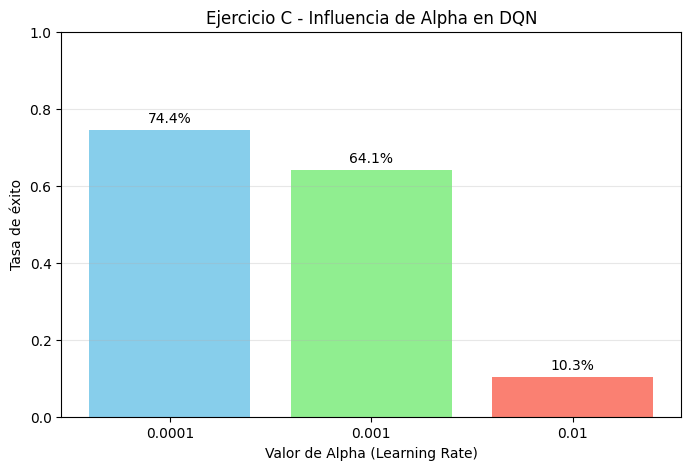

In [38]:

# Ejercicio C - Comparación de tasas de éxito según alpha
# Utilizo los resultados de los tres modelos ya entrenados.

alphas = list(resultados_C.keys())
tasas = list(resultados_C.values())

plt.figure(figsize=(8, 5))
barras = plt.bar(
    [str(a) for a in alphas],
    tasas,
    color=['skyblue', 'lightgreen', 'salmon']
)

plt.title('Ejercicio C - Influencia de Alpha en DQN')
plt.xlabel('Valor de Alpha (Learning Rate)')
plt.ylabel('Tasa de éxito')
plt.ylim(0, 1)

for barra, tasa in zip(barras, tasas):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.02,
        f'{tasa:.1%}',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.show()


### Conclusiones del ejercicio C

Para este experimento entrené tres modelos DQN modificando únicamente la tasa de aprendizaje (`lr`), que representa alpha en esta implementación, y manteniendo gamma en 0.95.

Los resultados obtenidos fueron:

-**Alpha 0.0001:** 74,4% de éxito.

-**Alpha 0.001:** 64,1% de éxito.

-**Alpha 0.01:** 10,3% de éxito.


Observé que el modelo con alpha bajo obtuvo el mejor resultado. En cambio, el valor más alto produjo un desempeño bastante inferior.

Esto puede relacionarse con la magnitud de los ajustes de los pesos de la red neuronal. Una tasa de aprendizaje elevada puede generar actualizaciones demasiado grandes y dificultar el aprendizaje de una política efectiva.

También observé que un valor de pérdida más bajo no garantiza una mejor tasa de éxito.

**Concluyo que la elección de alpha influye en el desempeño de DQN**, y que en este experimento los valores más bajos funcionaron mejor. Para confirmar si este comportamiento se mantiene, sería necesario repetir los entrenamientos con distintas semillas.

## Referencias y herramientas utilizadas

**Material de base**
- Notebook original de la actividad TP3 — Aprendizaje por Refuerzo en FrozenLake.

**Documentación técnica**
- [Gymnasium — FrozenLake](https://gymnasium.farama.org/environments/toy_text/frozen_lake/)
- [PyTorch — Documentación oficial](https://docs.pytorch.org/docs/stable/index.html)
- [PyTorch — Adam Optimizer](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

**Uso de inteligencia artificial**

Utilicé ChatGPT como herramienta de apoyo para comprender conceptos de aprendizaje por refuerzo, organizar los experimentos, revisar el código y analizar los resultados obtenidos.

Las clases y los métodos principales provienen del notebook original. Para resolver las consignas reutilicé esas implementaciones, ajustando los hiperparámetros y la cantidad de episodios según cada experimento.

Las interpretaciones y conclusiones se basan en los resultados de las ejecuciones realizadas.